# Buổi B7: Thực hành tổng hợp, từ đề bài đến bản báo cáo cuối

**Hiện trường.** Sau sáu buổi, ban giám đốc bệnh viện muốn có **một văn bản duy nhất** từ chị Hạnh, trả lời ba câu hỏi:

1. **Dùng mô hình nào** để xếp hạng bệnh nhân cần theo dõi sát?
2. **Cần những xét nghiệm nào** (mỗi chỉ số tốn tiền)?
3. **Có thể tin đến đâu**: sai bao nhiêu, yếu ở nhóm nào?

Đây là buổi *ráp mọi thứ đã học ở phần B thành một cuộc điều tra trọn vẹn*, theo đúng thứ tự một người làm dữ liệu chuyên nghiệp.

**Mindset của người làm dữ liệu:** kết quả cuối không phải là "mô hình có điểm cao nhất" mà là **một khuyến nghị có thể bảo vệ**: chọn bằng quy tắc rõ ràng, chấm một lần, nói thẳng điểm yếu.

**Lưu ý:** dữ liệu mẫu để học, không dùng để chẩn đoán. Buổi này dùng lại cú pháp từ A1 đến B6; chỉ giải thích điều **mới**.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Niêm phong tập thi và dựng mốc |
| Chặng 2 | Cuộc thi các mô hình bằng kiểm định chéo lặp |
| Chặng 3 | Chọn bằng quy tắc: ngang nhau thì chọn đơn giản |
| Chặng 4 | Mở niêm phong: chấm đúng một lần, rồi xẻ theo nhóm |
| Chặng 5 | Viết bản báo cáo cho ban giám đốc |
| Chặng 6 | Đóng gói thành khung dùng lại được cho bộ dữ liệu khác |

## Chặng 1: Niêm phong tập thi và dựng mốc

**Câu hỏi:** điều đầu tiên một người chuyên nghiệp làm với dữ liệu là gì?

**Cất tập thi đi.** Từ giờ đến chặng 4, ta không nhìn, không chấm, không đụng đến nó. Mọi so sánh và chọn lựa diễn ra **chỉ trên tập học**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
patients = load_diabetes(as_frame=True, scaled=False).frame
X = patients.drop(columns="target")
y = patients["target"]
X_train, X_sealed, y_train, y_sealed = train_test_split(X, y, test_size=0.2, random_state=42)
print("Working set:", X_train.shape, "| sealed test set:", X_sealed.shape, "(not touched until stage 4)")

Working set: (353, 10) | sealed test set: (89, 10) (not touched until stage 4)


**Giải thích từng dòng**

- `from sklearn... import ...; patients = ...; X, y = ...`: (đã học) dữ liệu bệnh nhân, mười cột đề, đáp án `target`.
- `X_train, X_sealed, y_train, y_sealed = train_test_split(...)`: (đã học) chia 80/20, hạt giống 42. Ta đặt tên `X_sealed` (**niêm phong**) thay cho `X_test` để nhắc mình: *bộ này chưa được mở*.

**Cách đọc:** 353 bệnh nhân để làm việc, **89 bệnh nhân được niêm phong**. Nếu ta cứ "liếc" tập thi để thử mô hình, rồi chọn cái nào đẹp nhất, thì điểm cuối cùng trở thành điểm của một cuộc thi mà ta đã *xem trước đề*. Quy tắc này đã có từ A4; ở đây ta thực hành nghiêm túc.

Trước mọi thứ, hãy dựng **mốc**: mô hình lười đoán trung bình. Mọi mô hình khác phải thắng nó.

## Chặng 2: Cuộc thi các mô hình bằng kiểm định chéo lặp

**Câu hỏi:** làm sao so chín mô hình công bằng khi chỉ dùng tập học?

Ở B6 ta biết **kiểm định chéo** (CV): chia tập học thành k phần, lần lượt mỗi phần làm tập kiểm định. Nâng cấp: **lặp lại** cả quy trình với cách chia khác (`RepeatedKFold`): 5 phần × 4 lần lặp = **20 điểm số** cho mỗi mô hình, đủ để thấy độ dao động.

In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_score, RepeatedKFold

def pick(cols):
    return ColumnTransformer([("keep", "passthrough", cols)])

candidates = {
    "lazy (mean)": DummyRegressor(),
    "BMI only": make_pipeline(pick(["bmi"]), StandardScaler(), LinearRegression()),
    "3 columns (bmi, s5, bp)": make_pipeline(pick(["bmi", "s5", "bp"]), StandardScaler(), LinearRegression()),
    "all 10, plain": make_pipeline(StandardScaler(), LinearRegression()),
    "all 10, Ridge": make_pipeline(StandardScaler(), Ridge(alpha=30)),
    "Lasso alpha=3 (7 cols)": make_pipeline(StandardScaler(), Lasso(alpha=3, max_iter=20000)),
    "Lasso alpha=10 (4 cols)": make_pipeline(StandardScaler(), Lasso(alpha=10, max_iter=20000)),
    "65 columns, plain": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
    "65 columns, Ridge": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), Ridge(alpha=200)),
}
folds = RepeatedKFold(n_splits=5, n_repeats=4, random_state=0)

**Giải thích từng dòng**

- `from sklearn... import ... (sáu dòng)`: (đã học) mọi mô hình và công cụ chế biến của phần B, cộng hai công cụ mới ở cuối: `cross_val_score` và `RepeatedKFold`.
- `def pick(cols): return ColumnTransformer([("keep", "passthrough", cols)])`: (đã học `ColumnTransformer` ở B4) dùng với một mục đích mới: **chọn một số cột ngay trong pipeline**. `"passthrough"` nghĩa là "cho đi qua nguyên xi", nên chỉ các cột trong `cols` được giữ lại. Nhờ vậy mô hình "3 cột" nhận được cả bảng 10 cột nhưng tự chọn đúng 3 cột, thay vì ta phải cắt bảng bằng tay.
- `candidates = {tên: mô_hình, ...}`: (đã học ở B6) chín thí sinh, mỗi cái là **một pipeline hoàn chỉnh** (chế biến + mô hình). Chọn α (30, 3, 10, 200) từ vùng đẹp ta đã khảo sát ở B6, **không** nhìn tập thi.
- `folds = RepeatedKFold(n_splits=5, n_repeats=4, random_state=0)`: **mới:** quy ước chia kiểm định chéo: 5 phần, lặp 4 lần với cách chia khác nhau; hạt giống 0 để lặp lại được.

In [4]:
rows = []
for name, model in candidates.items():
    r2 = cross_val_score(model, X_train, y_train, cv=folds, scoring="r2")
    mae = -cross_val_score(model, X_train, y_train, cv=folds, scoring="neg_mean_absolute_error")
    rows.append({"model": name, "R2": r2.mean(), "R2 std": r2.std(), "MAE": mae.mean(), "MAE std": mae.std(), "R2 SE": r2.std() / np.sqrt(len(r2))})
contest = pd.DataFrame(rows).set_index("model")
contest.round(3)

,R2,R2 std,MAE,MAE std,R2 SE
model,,,,,
lazy (mean),-0.016,0.015,66.580,4.221,0.003
BMI only,0.349,0.071,51.694,3.685,0.016
"3 columns (bmi, s5, bp)",0.463,0.064,46.817,3.366,0.014
"all 10, plain",0.493,0.065,44.718,3.294,0.014
"all 10, Ridge",0.494,0.059,44.847,3.411,0.013
Lasso alpha=3 (7 cols),0.485,0.055,45.569,3.386,0.012
Lasso alpha=10 (4 cols),0.445,0.049,48.243,3.587,0.011
"65 columns, plain",0.330,0.131,50.104,4.056,0.029
"65 columns, Ridge",0.494,0.061,44.969,3.746,0.014


**Giải thích từng dòng**

- `cross_val_score(model, X_train, y_train, cv=folds, scoring="r2")`: **mới:** một lệnh làm hết: với mỗi lần chia trong `folds`, **học lại** pipeline trên phần học, **chấm** trên phần kiểm định, trả về **mảng 20 điểm**. Vì mô hình là pipeline nên chế biến cũng được `fit` lại **trong từng lần**: không rò rỉ.
- `scoring="neg_mean_absolute_error"`: sklearn quy ước **"điểm càng cao càng tốt"**, nên với MAE (càng thấp càng tốt) nó trả về **số âm của MAE**. Ta thêm dấu `-` phía trước để lấy lại MAE dương.
- `r2.std() / np.sqrt(len(r2))`: **sai số chuẩn** (standard error) của điểm trung bình: độ lệch chuẩn chia căn bậc hai số điểm. Nó đo *"con số trung bình này đáng tin đến đâu"* (cần cho chặng 3).
- `contest = pd.DataFrame(rows).set_index("model")`: `.set_index("model")` **biến cột tên mô hình thành nhãn dòng**.

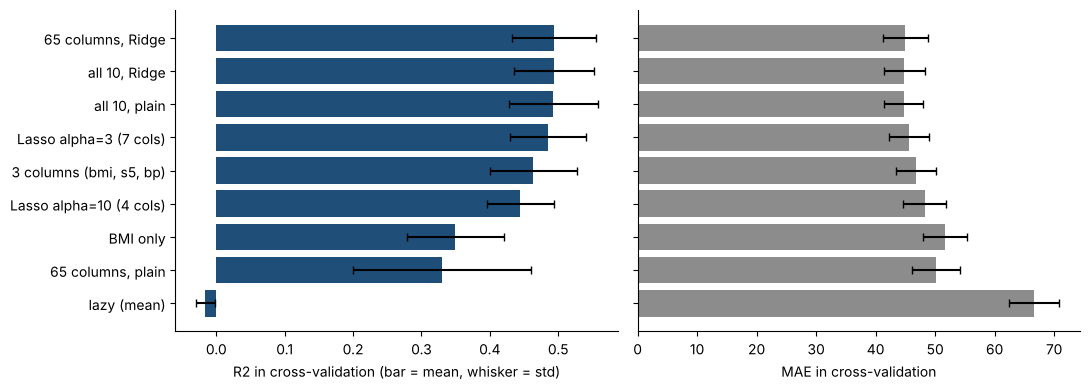

In [5]:
ordered = contest.sort_values("R2")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].barh(ordered.index, ordered["R2"], xerr=ordered["R2 std"], color=BLUE, capsize=3)
axes[0].set_xlabel("R2 in cross-validation (bar = mean, whisker = std)")
axes[1].barh(ordered.index, ordered["MAE"], xerr=ordered["MAE std"], color=GRAY, capsize=3)
axes[1].set_xlabel("MAE in cross-validation")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `ordered = contest.sort_values("R2")`: xếp các mô hình từ thấp đến cao theo R².
- `axes[0].barh(..., xerr=ordered["R2 std"], color=BLUE, capsize=3)`: (đã học `barh`, `errorbar` ở A4) **mới:** `xerr=` thêm **vạch dao động** (râu) theo chiều ngang cho mỗi thanh; `capsize` là độ rộng nắp râu. Râu dài nghĩa là điểm số **dao động nhiều** qua các lần chia.
- `fig, axes = plt.subplots(1, 2, ..., sharey=True)`: (đã học) hai ô chung nhãn dòng: ô trái R², ô phải MAE.

**Cách đọc**

- **Con số (R² trung bình qua 20 lần):** mô hình lười **−0,02**; BMI một mình **0,35**; ba cột **0,46**; mười cột thường **0,49**; Ridge **0,49**; Lasso 7 cột **0,49** (0,485); Lasso 4 cột **0,45**; 65 cột trần **0,33**; 65 cột có Ridge **0,49**. MAE đi ngược: từ 66,6 (lười) xuống khoảng 44,7 đến 45,6 (nhóm đầu).
- **Bức tranh:** bốn thanh dài nhất (mười cột thường, Ridge, Lasso 7 cột, 65 cột Ridge) **gần như bằng nhau**; **râu của chúng chồng lên nhau** gần hết (râu dài cỡ 0,06). Mô hình 65 cột trần có râu **dài gấp đôi** (0,13): vừa thấp vừa **bấp bênh**.
- **Điểm cốt lõi:** chênh lệch giữa các mô hình hàng đầu (0,485 đến 0,494) **nhỏ hơn nhiều** độ dao động giữa các lần chia (0,06). Nói cách khác, *dữ liệu này không đủ mạnh để phân biệt chúng*. Câu hỏi "ai cao điểm nhất" **không có câu trả lời đáng tin**. Ta cần một quy tắc khác để chọn.

## Chặng 3: Chọn bằng quy tắc, ngang nhau thì chọn đơn giản

**Câu hỏi:** nếu năm mô hình "ngang nhau", chọn ai?

Quy tắc thực hành phổ biến, gọi là **quy tắc một sai số chuẩn**:

1. Tìm mô hình có điểm trung bình **cao nhất**.
2. Gom mọi mô hình có điểm **không thấp hơn điểm cao nhất trừ một sai số chuẩn** (ở đó, chênh lệch nằm trong vùng nhiễu).
3. Trong nhóm đó, chọn mô hình **đơn giản nhất** (ít cột, ít phức tạp nhất).

Cái giá của sự đơn giản đã nằm trong "một sai số chuẩn"; ta chấp nhận mất tối đa chừng ấy.

In [6]:
best = contest["R2"].idxmax()
threshold = contest.loc[best, "R2"] - contest.loc[best, "R2 SE"]
eligible = contest[contest["R2"] >= threshold].copy()
columns_used = {"lazy (mean)": 0, "BMI only": 1, "3 columns (bmi, s5, bp)": 3, "all 10, plain": 10, "all 10, Ridge": 10,
                "Lasso alpha=3 (7 cols)": 7, "Lasso alpha=10 (4 cols)": 4, "65 columns, plain": 65, "65 columns, Ridge": 65}
eligible["columns"] = pd.Series(columns_used)
print("Best by mean R2:", best, "| eligible threshold:", round(threshold, 3))
eligible.sort_values("columns")[["R2", "R2 SE", "MAE", "columns"]].round(3)

Best by mean R2: 65 columns, Ridge | eligible threshold: 0.481


,R2,R2 SE,MAE,columns
model,,,,
Lasso alpha=3 (7 cols),0.485,0.012,45.569,7
"all 10, plain",0.493,0.014,44.718,10
"all 10, Ridge",0.494,0.013,44.847,10
"65 columns, Ridge",0.494,0.014,44.969,65


**Giải thích từng dòng**

- `best = contest["R2"].idxmax()`: (đã học `idxmin` ở B5) `idxmax` là bản đối xứng: **nhãn dòng của giá trị lớn nhất**, tức tên mô hình điểm cao nhất.
- `threshold = ... - contest.loc[best, "R2 SE"]`: ngưỡng = điểm cao nhất trừ một sai số chuẩn của chính nó.
- `eligible = contest[contest["R2"] >= threshold].copy()`: (đã học lọc dòng) giữ các mô hình đạt ngưỡng.
- `columns_used = {...}; eligible["columns"] = pd.Series(columns_used)`: ta ghi tay **số cột mỗi mô hình thực sự dùng** (thước đo độ đơn giản). `pd.Series(từ_điển)` đổi từ điển thành cột, ghép đúng dòng theo tên mô hình.
- `eligible.sort_values("columns")[[...]]`: xếp từ ít cột đến nhiều cột để dễ chọn.

**Cách đọc**

- **Con số:** mô hình điểm trung bình cao nhất là **65 cột có Ridge** (R² 0,494, bằng Ridge mười cột đến ba chữ số thập phân); ngưỡng chấp nhận khoảng **0,481** (0,494 trừ sai số chuẩn khoảng 0,014). Có **bốn mô hình đạt ngưỡng**: Lasso 7 cột (0,485), Ridge mười cột, mười cột thường và 65 cột có Ridge.
- **Bức tranh:** trong bốn mô hình đạt ngưỡng, **đơn giản nhất** (ít cột nhất) là **Lasso α = 3 với 7 cột**. Hai mô hình nhẹ hơn nữa (ba cột: 0,463; Lasso 4 cột: 0,445) **rơi dưới ngưỡng**: bỏ thêm cột thì ta mất nhiều hơn mức nhiễu cho phép.
- **Quyết định:** chọn **Lasso α = 3, 7 cột** (`sex`, `bmi`, `bp`, `s1`, `s3`, `s5`, `s6`). Chỉ cần 7 xét nghiệm thay vì 10, mà điểm gần như bằng mô hình tốt nhất.
- **Điều đáng chú ý:** quy tắc này **không** chọn mô hình 65 cột phức tạp dù nó nhỉnh nhất trên giấy. Nó chọn *đơn giản nhất trong nhóm ngang nhau*, theo nguyên tắc ta đã nói từ B5.

## Chặng 4: Mở niêm phong, chấm đúng một lần, rồi xẻ theo nhóm

**Câu hỏi:** mô hình đã chọn sẽ làm gì trên 89 bệnh nhân chưa ai nhìn thấy?

Ta học mô hình đã chọn trên **toàn bộ tập học** rồi chấm **một lần duy nhất** trên tập niêm phong, kèm hai mốc: mô hình lười và mô hình "chọn ngẫu nhiên".

In [7]:
from sklearn.metrics import mean_absolute_error
final = candidates["Lasso alpha=3 (7 cols)"].fit(X_train, y_train)
lazy = candidates["lazy (mean)"].fit(X_train, y_train)
pred_final, pred_lazy = final.predict(X_sealed), lazy.predict(X_sealed)

def top_k_mean(pred, k=10):
    return y_sealed.to_numpy()[np.argsort(-pred)[:k]].mean()

final_report = pd.DataFrame({
    "MAE": [mean_absolute_error(y_sealed, pred_final), mean_absolute_error(y_sealed, pred_lazy)],
    "R2": [final.score(X_sealed, y_sealed), lazy.score(X_sealed, y_sealed)],
    "top-10 mean": [top_k_mean(pred_final), y_sealed.mean()],
}, index=["chosen model", "lazy / random pick"]).round(2)
print("Best possible top-10 mean:", round(np.sort(y_sealed.to_numpy())[::-1][:10].mean(), 1))
final_report

Best possible top-10 mean: 276.7


,MAE,R2,top-10 mean
chosen model,43.04,0.47,240.50
lazy / random pick,64.01,-0.01,145.78


**Giải thích từng dòng**

- `final = candidates["Lasso alpha=3 (7 cols)"].fit(X_train, y_train)`: lấy mô hình đã chọn từ từ điển và **học lại trên toàn bộ tập học**. (Trong CV mỗi lần chỉ học trên bốn phần năm.)
- `pred_final, pred_lazy = ...`: dự đoán của hai mô hình trên tập niêm phong. Đây là lần **đầu tiên và duy nhất** tập này bị chạm tới.
- `def top_k_mean(pred, k=10):`: (đã học) thước đo quyết định: điểm thật trung bình của k người có điểm đoán cao nhất. `k=10` là **tham số có giá trị mặc định** (đã học ở A5).
- `"top-10 mean": [top_k_mean(pred_final), y_sealed.mean()]`: với mô hình lười, "chọn 10 người" vô nghĩa (mọi người cùng điểm), nên mốc đúng là **chọn ngẫu nhiên** = trung bình cả tập thi.

**Cách đọc**

- **Con số:** trên 89 bệnh nhân niêm phong: **MAE 42,8** (lười: 64,0), **R² 0,47** (lười: −0,01), **chọn 10 người** có điểm thật trung bình **240** (ngẫu nhiên: 146; mức hoàn hảo: 277).
- **Bức tranh:** con số cuối cùng **khớp với ước lượng CV ở chặng 2** (R² 0,47 so với 0,485): ta không bị ảo tưởng, nhờ đã niêm phong và chọn có quy tắc. Mô hình lấy được **khoảng 72% khoảng cách** từ chọn ngẫu nhiên (146) đến mức hoàn hảo (277): (240,5 − 145,8) / (276,7 − 145,8).
- **Cách báo cáo con số cuối:** *"R² khoảng 0,47 (kiểm định chéo cho thấy dao động từ khoảng 0,43 đến 0,54 tùy cách chia)"* thay vì "0,47" trơn.

Còn **điểm yếu**? Ta xẻ sai số theo nhóm, bài học từ B1:

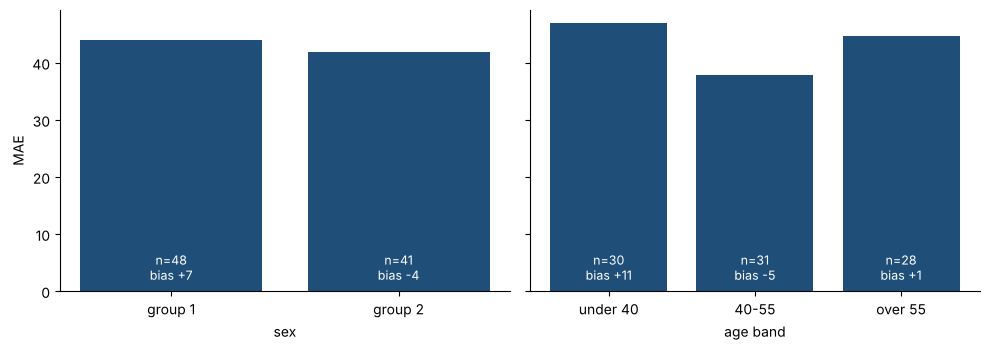

In [8]:
report = pd.DataFrame({
    "sex": X_sealed["sex"].map({1: "group 1", 2: "group 2"}),
    "age band": pd.cut(X_sealed["age"], [0, 40, 55, 100], labels=["under 40", "40-55", "over 55"]),
    "actual": y_sealed,
    "abs_error": (y_sealed - pred_final).abs(),
    "signed_error": y_sealed - pred_final,
})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, col in zip(axes, ["sex", "age band"]):
    g = report.groupby(col, observed=True).agg(n=("actual", "size"), MAE=("abs_error", "mean"), bias=("signed_error", "mean")).round(1)
    ax.bar(g.index.astype(str), g["MAE"], color=BLUE)
    for i, (n, b) in enumerate(zip(g["n"], g["bias"])):
        ax.text(i, 2, f"n={n}\nbias {b:+.0f}", ha="center", color="white", fontsize=9)
    ax.set_xlabel(col)
axes[0].set_ylabel("MAE")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `"sex": X_sealed["sex"].map({1: "group 1", 2: "group 2"})`: (đã học `.map`) đặt tên cho hai nhóm giới (mã 1 và 2).
- `"age band": pd.cut(X_sealed["age"], [0, 40, 55, 100], labels=[...])`: **mới:** `pd.cut(cột, các_mốc, labels=tên)` **cắt một cột số thành các nhóm** theo mốc: tuổi 0 đến 40, 40 đến 55, 55 đến 100, mỗi nhóm một nhãn.
- `"signed_error": y_sealed - pred_final`: sai số **có dấu** (thật − đoán): dương là máy đoán thấp. Trung bình có dấu của một nhóm gọi là **độ lệch** (bias): nhóm đó bị đoán **thấp hay cao một cách có hệ thống**.
- `report.groupby(col, observed=True).agg(...)`: (đã học `groupby` + `agg`) `observed=True` chỉ giữ các nhóm có dữ liệu thật (cần cho cột nhóm tạo bằng `pd.cut`).
- `ax.text(i, 2, f"n={n}\\nbias {b:+.0f}", ...)`: (đã học `:+.0f` ở A5) viết **số người** và **độ lệch** vào chân mỗi cột.
- `for i, (n, b) in enumerate(zip(g["n"], g["bias"])):`: (đã học `enumerate` ở B6, `zip` ở A3) lặp qua từng nhóm với số thứ tự `i` để biết đặt chữ ở cột nào.

**Cách đọc**

- **Con số:** hai nhóm giới có MAE gần nhau (**44,0** và **41,9**) với độ lệch **+7** và **−4**. Ba nhóm tuổi: dưới 40 tuổi MAE **46,9** và độ lệch **+11**; từ 40 đến 55 tuổi MAE **37,8** và độ lệch −5; trên 55 tuổi MAE **44,7** và độ lệch +1.
- **Bức tranh:** nổi bật nhất là nhóm **dưới 40 tuổi**: sai nhiều nhất và bị đoán **thấp hơn thực tế trung bình 11 điểm** (máy "đánh giá nhẹ" bệnh nhân trẻ). Nhóm 40 đến 55 tuổi được đoán tốt nhất.
- **Lưu ý thành thật:** mỗi nhóm chỉ có 28 đến 48 người, nên chênh lệch kiểu 38 so với 47 **có thể chỉ là may rủi** (nhớ A4). Dùng kết quả này làm **giả thuyết để kiểm tra** trên dữ liệu lớn hơn, không phải kết luận.

**Cách dùng đúng:** nhóm có MAE cao hoặc độ lệch rõ là nơi cần nói trong báo cáo (*"mô hình có thể đánh giá nhẹ bệnh nhân trẻ"*), và là gợi ý cho vòng cải tiến sau.

**Cách dùng đúng:** những nhóm có MAE cao hoặc độ lệch rõ là nơi cần nói trong báo cáo: *"mô hình kém tin cậy hơn ở nhóm X"*, và là gợi ý cho vòng cải tiến sau, không phải kết luận chắc chắn.

## Chặng 5: Viết bản báo cáo cho ban giám đốc

**Câu hỏi:** làm sao biến cả cuộc điều tra thành một trang giấy?

Một bản báo cáo tốt trả lời ba câu hỏi của ban giám đốc bằng **con số thật, từ code**, không phải con số gõ tay. Ta cho Python điền vào khuôn:

In [9]:
chosen_cols = X.columns[final[-1].coef_ != 0].tolist()
dropped_cols = X.columns[final[-1].coef_ == 0].tolist()
fin = final_report.loc["chosen model"]
cv_row = contest.loc["Lasso alpha=3 (7 cols)"]
summary = f"""
REPORT: ranking patients for close monitoring (sample data, NOT for diagnosis)

1. Model: Lasso regression (alpha=3) on standardized columns, chosen from 9 candidates
   by repeated 5-fold cross-validation on 353 patients, then checked once on 89 sealed patients.
2. Tests needed: {len(chosen_cols)} of 10 -> {", ".join(chosen_cols)}.
   Dropped as not adding value: {", ".join(dropped_cols)}.
3. Trust:
   - Typical error: {fin["MAE"]:.0f} points (guessing the average: {final_report.loc["lazy / random pick", "MAE"]:.0f}).
   - R2 on sealed patients: {fin["R2"]:.2f}  (cross-validation said {cv_row["R2"]:.2f} +/- {cv_row["R2 std"]:.2f}).
   - Top-10 monitoring list: true average score {fin["top-10 mean"]:.0f} vs {final_report.loc["lazy / random pick", "top-10 mean"]:.0f} by random pick.
4. Limits: explains about half of the variation, not more. Coefficients of correlated columns
   (s1 vs s2) must not be read as causes. Sealed set is only {len(X_sealed)} patients, so every number moves a little with a different split.
"""
print(summary)


REPORT: ranking patients for close monitoring (sample data, NOT for diagnosis)

1. Model: Lasso regression (alpha=3) on standardized columns, chosen from 9 candidates
   by repeated 5-fold cross-validation on 353 patients, then checked once on 89 sealed patients.
2. Tests needed: 7 of 10 -> sex, bmi, bp, s1, s3, s5, s6.
   Dropped as not adding value: age, s2, s4.
3. Trust:
   - Typical error: 43 points (guessing the average: 64).
   - R2 on sealed patients: 0.47  (cross-validation said 0.48 +/- 0.06).
   - Top-10 monitoring list: true average score 240 vs 146 by random pick.
4. Limits: explains about half of the variation, not more. Coefficients of correlated columns
   (s1 vs s2) must not be read as causes. Sealed set is only 89 patients, so every number moves a little with a different split.



**Giải thích từng dòng**

- `chosen_cols = X.columns[final[-1].coef_ != 0].tolist()`: (đã học ở B6) tên các cột mà Lasso giữ lại, đọc **từ mô hình**, không gõ tay.
- `fin = final_report.loc["chosen model"]`: (đã học `.loc`) lấy dòng kết quả của mô hình đã chọn.
- `summary = f"""..."""`: (đã học f-string) **chuỗi nhiều dòng** viết trong ba dấu nháy kép `"""`, bên trong chèn các giá trị bằng `{...}`. Mỗi `{...}` được thay bằng số thật khi chạy.
- `{", ".join(chosen_cols)}`: **mới:** `", ".join(danh_sách)` **nối các phần tử thành một chuỗi**, cách nhau bằng dấu phẩy và dấu cách.
- `{fin["MAE"]:.0f}`: (đã học `:.0f`) làm tròn số nguyên.

**Cách đọc:** bản báo cáo ngắn nhưng đủ ba mục ban giám đốc cần và một mục **giới hạn**. Mỗi con số đều là **kết quả của code**: nếu ngày mai dữ liệu hoặc mô hình đổi, chạy lại là báo cáo tự cập nhật, không có số nào sót lại từ lần trước.

**Phần "giới hạn" không phải để đẹp.** Nó trả lời câu hỏi mà một người thông minh sẽ hỏi: *"Vậy có chỗ nào tôi không nên tin nó?"* Một báo cáo chỉ khoe điểm cao thì ít được tin hơn một báo cáo nói thẳng điểm yếu.

**Khi nào KHÔNG nên dùng mô hình này** (để ghi vào hồ sơ):

- Để **chẩn đoán hoặc quyết định điều trị**: nó chỉ gợi ý *thứ tự ưu tiên theo dõi*; người quyết là bác sĩ.
- Khi bệnh nhân **khác nhóm** với dữ liệu học (tuổi, vùng, thiết bị xét nghiệm khác).
- Khi quy tắc đơn giản đã đủ tốt (ví dụ chỉ xếp theo BMI vẫn bắt được phần lớn người nặng).

## Chặng 6: Đóng gói thành khung dùng lại được cho bộ dữ liệu khác

**Câu hỏi:** kỹ năng ở buổi này có dùng được cho dữ liệu khác không?

Ta gói quy trình "mốc → cuộc thi bằng kiểm định chéo → quy tắc một sai số chuẩn" vào một **hàm** nhận bất kỳ (X, y) nào, rồi thử trên **bộ dữ liệu hoàn toàn khác**: hoa iris, đáp án là chiều rộng cánh hoa (B1).

In [10]:
def investigate(X, y, candidates, columns_used):
    X_work, X_seal, y_work, y_seal = train_test_split(X, y, test_size=0.2, random_state=42)
    cv = RepeatedKFold(n_splits=5, n_repeats=4, random_state=0)
    rows = []
    for name, model in candidates.items():
        r2 = cross_val_score(model, X_work, y_work, cv=cv, scoring="r2")
        rows.append({"model": name, "R2": r2.mean(), "SE": r2.std() / np.sqrt(len(r2)), "columns": columns_used[name]})
    table = pd.DataFrame(rows).set_index("model")
    best = table["R2"].idxmax()
    ok = table[table["R2"] >= table.loc[best, "R2"] - table.loc[best, "SE"]]
    choice = ok["columns"].idxmin()
    chosen = candidates[choice].fit(X_work, y_work)
    return table.round(3), choice, round(chosen.score(X_seal, y_seal), 3)

**Giải thích từng dòng**

- `def investigate(X, y, candidates, columns_used):`: (đã học `def`) hàm nhận **bảng đề, cột đáp án, từ điển thí sinh, và số cột mỗi thí sinh dùng**, rồi chạy cả quy trình.
- `X_work, X_seal, y_work, y_seal = train_test_split(...)`: niêm phong như chặng 1.
- `cv = RepeatedKFold(...); for name, model in candidates.items(): ...`: cuộc thi bằng kiểm định chéo như chặng 2.
- `ok = table[table["R2"] >= ... - ...]; choice = ok["columns"].idxmin()`: quy tắc một sai số chuẩn như chặng 3: trong nhóm đạt ngưỡng, `idxmin` của cột `columns` cho **mô hình ít cột nhất**.
- `return table.round(3), choice, round(chosen.score(X_seal, y_seal), 3)`: trả về **ba thứ cùng lúc**: bảng cuộc thi, tên mô hình được chọn, điểm trên tập niêm phong. Cách trả về nhiều giá trị này đã học ở A1 (tuple).

In [11]:
from sklearn.datasets import load_iris
flowers = load_iris(as_frame=True).frame.rename(columns={"petal length (cm)": "petal_length", "petal width (cm)": "petal_width", "sepal length (cm)": "sepal_length", "sepal width (cm)": "sepal_width"})
Xi, yi = flowers[["sepal_length", "sepal_width", "petal_length"]], flowers["petal_width"]
iris_candidates = {
    "lazy (mean)": DummyRegressor(),
    "petal_length only": make_pipeline(pick(["petal_length"]), StandardScaler(), LinearRegression()),
    "all 3, plain": make_pipeline(StandardScaler(), LinearRegression()),
    "all 3, Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1)),
    "degree 2, plain": make_pipeline(PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()),
}
iris_cols = {"lazy (mean)": 0, "petal_length only": 1, "all 3, plain": 3, "all 3, Ridge": 3, "degree 2, plain": 9}
table, choice, sealed_r2 = investigate(Xi, yi, iris_candidates, iris_cols)
print(table)
print("Chosen:", choice, "| R2 on sealed iris flowers:", sealed_r2)

                      R2     SE  columns
model                                   
lazy (mean)       -0.072  0.016        0
petal_length only  0.920  0.005        1
all 3, plain       0.933  0.004        3
all 3, Ridge       0.931  0.004        3
degree 2, plain    0.932  0.004        9
Chosen: all 3, plain | R2 on sealed iris flowers: 0.927


**Giải thích từng dòng**

- `flowers = load_iris(...).frame.rename(columns={...})`: (đã học ở B1) hoa iris, đổi tên cột cho dễ gõ.
- `Xi, yi = flowers[["sepal_length", "sepal_width", "petal_length"]], flowers["petal_width"]`: đề: ba số đo; đáp án: chiều rộng cánh hoa.
- `iris_candidates = {...}; iris_cols = {...}`: năm thí sinh và số cột mỗi cái dùng (bậc 2 trên 3 cột sinh 9 cột). Dùng lại `pick` từ chặng 2.
- `table, choice, sealed_r2 = investigate(...)`: (đã học mở gói tuple ở A1) nhận ba kết quả của hàm.

**Cách đọc**

- **Con số:** mô hình lười R² **−0,07**; mô hình "chỉ chiều dài cánh hoa" **0,920**; ba cột thường **0,933**; ba cột Ridge 0,931; bậc 2 (9 cột) 0,932. Ngưỡng một sai số chuẩn là 0,933 − 0,004 = **0,929**. Mô hình một cột (0,920) **thấp hơn ngưỡng**, nên bị loại; trong nhóm đạt ngưỡng, quy tắc chọn **ba cột thường** (ít cột nhất trong nhóm). Điểm trên tập niêm phong: **0,927**.
- **Bức tranh:** quy trình **không đổi** dù dữ liệu khác hẳn: iris không giống bệnh nhân, nhưng mốc, cuộc thi, quy tắc đơn giản, và niêm phong là **cùng một thói quen**. Ở đây chênh lệch giữa một cột và ba cột rất nhỏ (0,013) nhưng **ổn định** (sai số chuẩn chỉ 0,004), nên quy tắc coi đó là chênh lệch thật. Ở bệnh nhân, sai số chuẩn lớn gấp ba (0,014) nên cùng mức chênh nằm trong vùng nhiễu. *Mức nghiêm khắc của quy tắc phụ thuộc vào độ ồn của dữ liệu*, không phải vào khung.
- **Khung này là đồ nghề của bạn.** Gặp bộ dữ liệu hồi quy mới: chuẩn bị `candidates`, chạy `investigate`, rồi mở niêm phong và viết báo cáo như chặng 5.

## Phán quyết và bài học nghề

**Phán quyết cho ban giám đốc.** *Dùng Lasso α = 3, bảy xét nghiệm (`sex`, `bmi`, `bp`, `s1`, `s3`, `s5`, `s6`); sai trung bình khoảng 43 điểm, R² khoảng 0,47; chọn 10 người theo dõi bắt được 240 điểm so với 146 nếu chọn ngẫu nhiên. Chỉ dùng để gợi ý thứ tự theo dõi, không dùng để chẩn đoán.* Thêm một câu thật thà: *giải thích khoảng một nửa dao động, và con số dao động nhẹ theo mẫu.*

**Bài học nghề (tổng kết phần B).**

1. **Niêm phong tập thi** trước tiên; mọi lựa chọn chỉ dùng tập học.
2. **Dựng mốc** (mô hình lười, chọn ngẫu nhiên) trước khi khen mô hình.
3. **So mô hình bằng kiểm định chéo lặp**, nhìn cả **độ dao động**, không chỉ điểm trung bình.
4. **Ngang nhau thì chọn đơn giản** (quy tắc một sai số chuẩn).
5. **Chấm đúng một lần** trên tập niêm phong, rồi **xẻ sai số theo nhóm**.
6. **Báo cáo bằng con số lấy từ code**, kèm giới hạn và khi nào không nên dùng.
7. **Đóng gói thành khung** để dùng lại cho dữ liệu khác.

**Một điều thành thật:** nếu có ai hỏi "mô hình nào tốt nhất?", câu trả lời trung thực của buổi này là *"bốn mô hình ngang nhau, và ta chọn cái đơn giản nhất"*. Thói quen khoa học nằm ở chỗ chấp nhận câu trả lời đó thay vì chọn đại một cái rồi khẳng định nó là nhất.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Niêm phong tập thi; chỉ dùng tập học để chọn; dựng mốc lười và chọn ngẫu nhiên. |
| 2 | So nhiều mô hình bằng `cross_val_score` với `RepeatedKFold`; nhìn cả độ dao động (râu). |
| 3 | Quy tắc một sai số chuẩn: trong nhóm điểm ngang nhau, chọn mô hình đơn giản nhất. |
| 4 | Chấm một lần trên tập niêm phong; xẻ sai số theo nhóm; đo cả độ lệch có hệ thống. |
| 5 | Báo cáo bằng con số từ code, có mục giới hạn và khi nào không nên dùng. |
| 6 | Đóng gói quy trình thành hàm để dùng lại cho dữ liệu khác. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Chia tập học thành k phần, lần lượt thi | kiểm định chéo (cross-validation) | `cross_val_score(model, X, y, cv=...)` |
| Lặp việc chia nhiều lần cho chắc | kiểm định chéo lặp | `RepeatedKFold(n_splits=5, n_repeats=4)` |
| Điểm sklearn luôn "cao là tốt" | điểm âm của MAE | `scoring="neg_mean_absolute_error"` |
| Độ đáng tin của điểm trung bình | sai số chuẩn (SE) | `std / np.sqrt(n)` |
| Ngang nhau thì chọn đơn giản | quy tắc một sai số chuẩn | `R2 >= best - SE` |
| Đoán thấp hay cao một cách nhất quán | độ lệch (bias) | `(y - pred).mean()` |
| Cắt cột số thành nhóm | chia khoảng | `pd.cut(col, bins, labels)` |
| Nối danh sách thành chuỗi | join | `", ".join(list)` |
| Chọn cột ngay trong pipeline | bộ chọn cột | `ColumnTransformer([("keep", "passthrough", cols)])` |

**Thử thách tự làm**

1. Chạy `investigate` trên `load_wine(as_frame=True)`: đề là các cột hóa học trừ `alcohol` (chọn 3 đến 4 cột), đáp án là `alcohol`. Tự chuẩn bị `candidates` và `columns_used`. Quy tắc một sai số chuẩn chọn mô hình nào?
2. Quay lại chặng 3 của bệnh nhân, đổi "một sai số chuẩn" thành "hai sai số chuẩn". Mô hình được chọn có đổi không? Bạn rút ra gì về mức nghiêm khắc của quy tắc?
3. Viết bản báo cáo (như chặng 5) cho bộ hoa iris, gồm: mô hình chọn, cột dùng, sai số điển hình (cm), điểm yếu theo loài (dùng lại kỹ thuật chặng 4), và khi nào không nên dùng.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích vì sao phải niêm phong tập thi.
- [ ] Dựng cuộc thi nhiều mô hình bằng `cross_val_score` và đọc cả độ dao động.
- [ ] Áp dụng quy tắc một sai số chuẩn để chọn mô hình.
- [ ] Xẻ sai số theo nhóm và nói được nhóm nào kém tin cậy.
- [ ] Viết báo cáo có con số lấy từ code và mục giới hạn.
- [ ] Đóng gói quy trình thành hàm dùng lại cho dữ liệu khác.

## Phần thưởng (Tip pro): Phép thử đối chứng: huấn luyện trên đáp án bị xáo trộn


Một cách nhanh để **bắt lỗi rò rỉ dữ liệu** trong cả quy trình: cho máy học trên **đáp án đã xáo trộn ngẫu nhiên** (mất hết quan hệ thật với đề). Nếu quy trình sạch, R² phải **gần 0 hoặc âm**. Nếu R² *khá cao*, bạn đã vô tình để lọt thông tin của đáp án vào đề hoặc vào bước chọn mô hình. Chạy ô dưới:

In [12]:
rng = np.random.default_rng(0)
shuffled_y = pd.Series(rng.permutation(y_train.to_numpy()), index=y_train.index)
control = cross_val_score(candidates["Lasso alpha=3 (7 cols)"], X_train, shuffled_y, cv=folds, scoring="r2")
real = cross_val_score(candidates["Lasso alpha=3 (7 cols)"], X_train, y_train, cv=folds, scoring="r2")
print("R2 with real answers    :", round(real.mean(), 3))
print("R2 with shuffled answers:", round(control.mean(), 3), "(should be near 0 or negative)")

R2 with real answers    : 0.485
R2 with shuffled answers: -0.049 (should be near 0 or negative)


**Giải thích từng dòng**

- `shuffled_y = pd.Series(rng.permutation(y_train.to_numpy()), index=y_train.index)`: **mới:** `rng.permutation(mảng)` trả về mảng **xáo trộn ngẫu nhiên**: mỗi bệnh nhân bị gán đáp án của một người khác. Các giá trị y nguyên, chỉ **mất liên hệ** với đề. `index=...` giữ nhãn dòng cho ghép đúng.
- `control = cross_val_score(..., X_train, shuffled_y, ...)`: chạy **cùng quy trình** trên đáp án xáo trộn: đây là **nhóm đối chứng**.

**Cách đọc:** R² với đáp án thật khoảng **0,49** (0,485); với đáp án xáo trộn khoảng **−0,05** (gần 0, hơi âm). Đúng như mong đợi: quy trình **sạch**, không bịa ra điểm từ hư không. Ta nên chạy phép thử này mỗi khi dựng một quy trình mới, nhất là khi điểm cao đến mức đáng ngờ.